**Import all packages and datasets**

In [70]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    BaggingClassifier,
    RandomForestClassifier,
    VotingClassifier
)

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier

from sklearn.inspection import permutation_importance

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)

sns.set_style("whitegrid")

**Load the dataset**

In [71]:
data = load_breast_cancer(as_frame=True)

X=data.data
y=data.target

In [72]:
X.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


I see that most of the features that I can see contain floating point numerical values. 

In [73]:
y.head()

0    0
1    0
2    0
3    0
4    0
Name: target, dtype: int64

In [74]:

print(X.dtypes)
print(len(X.columns))
print(sum(X.isna().sum()))


mean radius                float64
mean texture               float64
mean perimeter             float64
mean area                  float64
mean smoothness            float64
mean compactness           float64
mean concavity             float64
mean concave points        float64
mean symmetry              float64
mean fractal dimension     float64
radius error               float64
texture error              float64
perimeter error            float64
area error                 float64
smoothness error           float64
compactness error          float64
concavity error            float64
concave points error       float64
symmetry error             float64
fractal dimension error    float64
worst radius               float64
worst texture              float64
worst perimeter            float64
worst area                 float64
worst smoothness           float64
worst compactness          float64
worst concavity            float64
worst concave points       float64
worst symmetry      

In [75]:
print(y.value_counts())


target
1    357
0    212
Name: count, dtype: int64


**Questions**
1. There are 569 observations in the dataset.
2. There are 30 predictor variables
3. The features are all numerical.
4. There are no missing values in the dataset.
5. There are 357 observations of benign and 212 of malignant.
6. The target is imbalanced.

In [76]:
#Understanding target variable
print(data.target_names)
print(y.value_counts())

['malignant' 'benign']
target
1    357
0    212
Name: count, dtype: int64


This shows me the balance of the target set and the names of each outcome.

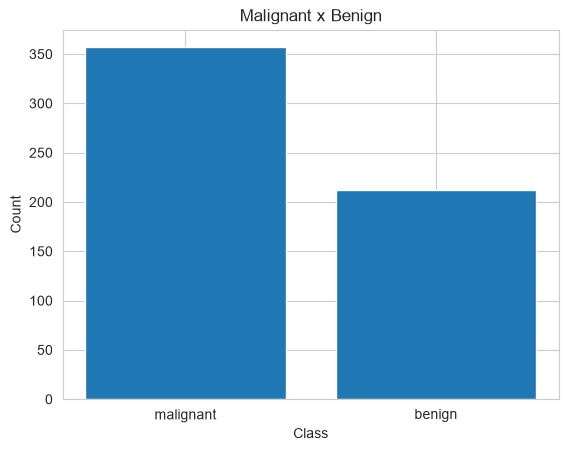

In [77]:
plt.bar(data.target_names, y.value_counts())
plt.title('Malignant x Benign')
plt.xlabel('Class')
plt.ylabel('Count')
plt.show()


**Questions**
1. The 0 represents benign cancer.
2. The 1 represents malignant cancer.
3. The malignant class has more observations.
4. We should consider class balance when evaluating a classification model because the bias could change based on the imbalance of the data.

In [78]:
#Splitting the data
X_train, X_test, y_train, y_test = train_test_split(
    X, 
    y, 
    test_size=0.2, 
    stratify=y, 
    random_state=42)


In [79]:
#Report
print(f"Training observations: {len(X_train)}")
print(f"Testing observations: {len(X_test)}")
print(f"Number of features: {len(X_train.columns)}")

Training observations: 455
Testing observations: 114
Number of features: 30


**Why do we use Stratify?**
To help with distributing imbalanced data to ensure the amount of bias is low.

In [80]:
#print(X_train.info())
print(y_train.info())

<class 'pandas.Series'>
Index: 455 entries, 546 to 474
Series name: target
Non-Null Count  Dtype
--------------  -----
455 non-null    int64
dtypes: int64(1)
memory usage: 7.1 KB
None


In [81]:
#Load and fit the tree model
tree = DecisionTreeClassifier(
    random_state=42
)

tree.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples

In [82]:
#Get predictions
y_pred_tree = tree.predict(X_test)

In [83]:
#Calculate accuracy
tree_accuracy = accuracy_score(
    y_test,
    y_pred_tree
)

print("Accuracy:", tree_accuracy)

Accuracy: 0.9122807017543859


In [84]:
#Calculate F1
tree_f1=f1_score(
    y_test,
    y_pred_tree
)

print("F1:", tree_f1)

F1: 0.9285714285714286


In [85]:
#Print classification report
print(
        classification_report(
            y_test,
            y_pred_tree,
            target_names = data.target_names
        )
)

              precision    recall  f1-score   support

   malignant       0.85      0.93      0.89        42
      benign       0.96      0.90      0.93        72

    accuracy                           0.91       114
   macro avg       0.90      0.92      0.91       114
weighted avg       0.92      0.91      0.91       114



**Questions**
1. The decision tree achieved an accuracy of 0.91
2. The F1 score was 0.93.
3. It is useful because we are able to compare the ensemble to the single model to actually see if we are improving performance of the model. Without the baseline, we wouldn't have any thing to compare the ensemble model to.
4. High variance means that the data is spread out farther from the mean.

**Bootstrapping!!!!**

In [86]:
#Understanding bootstrapping with a simple dataset.
observations = np.array([
    'A', 'B', 'C', 'D', 'E'
])

In [87]:
#Creating a bootstrap sample
bootstrap_sample = np.random.choice(
    observations,
    size= len(observations),
    replace= True
)

print(bootstrap_sample)

['A' 'C' 'E' 'E' 'C']


**Questions**
1. No, not every observation will appear in a bootstrap sample.
2. An observation can appear more than once.
3. Yes, each bootstrap sample does contain five observations.
4. It means that you can select a value multiple times 

In [88]:
for i in range(5):

    sample = np.random.choice(
        observations,
        size=len(observations),
        replace=True
    )

    print(
        f"Sample {i + 1}: {sample}"
    )

Sample 1: ['B' 'B' 'E' 'E' 'C']
Sample 2: ['E' 'A' 'A' 'B' 'A']
Sample 3: ['D' 'E' 'D' 'E' 'C']
Sample 4: ['D' 'C' 'B' 'B' 'E']
Sample 5: ['A' 'A' 'D' 'A' 'B']


**Questions**
1. They all contain different combinations of different observations in the data set.
2. No, they do not contain the same observations.
3. It ensures that the bias when training multiple models is low, not all models get the same sample so it allows us to train models better. 

**Written explanation**
1. It allows us to take the size of the dataset and then replace values with values from the original data set so when trained on it is randomized.

In [89]:
train_data = X_train.copy()

train_data["target"] = y_train.values

In [90]:
bootstrap_sample = train_data.sample(
    n=len(train_data),
    replace=True,
    random_state=42
)

In [91]:
bootstrap_sample.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
68,9.029,17.33,58.79,250.5,0.10660,0.14130,0.31300,0.04375,0.2111,0.08046,...,22.65,65.50,324.7,0.1482,0.4365,1.25200,0.17500,0.4228,0.11750,1
378,13.660,15.15,88.27,580.6,0.08268,0.07548,0.04249,0.02471,0.1792,0.05897,...,19.64,97.96,657.0,0.1275,0.3104,0.25690,0.10540,0.3387,0.09638,1
326,14.110,12.88,90.03,616.5,0.09309,0.05306,0.01765,0.02733,0.1373,0.05700,...,18.00,98.40,749.9,0.1281,0.1109,0.05307,0.05890,0.2100,0.07083,1
502,12.540,16.32,81.25,476.3,0.11580,0.10850,0.05928,0.03279,0.1943,0.06612,...,21.40,86.67,552.0,0.1580,0.1751,0.18890,0.08411,0.3155,0.07538,1
195,12.910,16.33,82.53,516.4,0.07941,0.05366,0.03873,0.02377,0.1829,0.05667,...,22.00,90.81,600.6,0.1097,0.1506,0.17640,0.08235,0.3024,0.06949,1


In [92]:
bootstrap_sample.index.nunique()

275

In [93]:
len(bootstrap_sample)

455

**Questions**
1. The bootstrap sample does have the same number of rows as the original training set.
2. No, they do not have the same number of observations.
3. These numbers are potentially different because the bootstrapping does not pick every row and may leave some out.
4. This tells me that sampling with replacement produces a more randomized dataset, possibly more balanced.

In [94]:
bagging_tree= BaggingClassifier(
        estimator=DecisionTreeClassifier(
            random_state=42
        ),
        n_estimators=100,
        random_state=42
)

In [95]:
bagging_tree.fit(
    X_train,
    y_train
)

,"estimator estimator: object, default=NoneThe base estimator to fit on random subsets of the dataset.If None, then the base estimator is a:class:`~sklearn.tree.DecisionTreeClassifier`... versionadded:: 1.2 `base_estimator` was renamed to `estimator`.",DecisionTreeC...ndom_state=42)
,"n_estimators n_estimators: int, default=10The number of base estimators in the ensemble.",100
,"random_state random_state: int, RandomState instance or None, default=NoneControls the random resampling of the original dataset(sample wise and feature wise).If the base estimator accepts a `random_state` attribute, a differentseed is generated for each instance in the ensemble.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"max_samples max_samples: int or float, default=NoneThe number of samples to draw from X to train each base estimator (withreplacement by default, see `bootstrap` for more details).- If None, then draw `X.shape[0]` samples irrespective of `sample_weight`.- If int, then draw `max_samples` samples.- If float, then draw `max_samples * X.shape[0]` unweighted samples or `max_samples * sample_weight.sum()` weighted samples.",None
,"max_features max_features: int or float, default=1.0The number of features to draw from X to train each base estimator (without replacement by default, see `bootstrap_features` for moredetails).- If int, then draw `max_features` features.- If float, then draw `max(1, int(max_features * n_features_in_))` features.",1.0
,"bootstrap bootstrap: bool, default=TrueWhether samples are drawn with replacement. If False, sampling withoutreplacement is performed. If fitting with `sample_weight`, it isstrongly recommended to choose True, as only drawing with replacementwill ensure the expected frequency semantics of `sample_weight`.",True
,"bootstrap_features bootstrap_features: bool, default=FalseWhether features are drawn with replacement.",False
,"oob_score oob_score: bool, default=FalseWhether to use out-of-bag samples to estimatethe generalization error. Only available if bootstrap=True.",False
,"warm_start warm_start: bool, default=FalseWhen set to True, reuse the solution of the previous call to fitand add more estimators to the ensemble, otherwise, just fita whole new ensemble. See :term:`the Glossary <warm_start>`... versionadded:: 0.17 *warm_start* constructor parameter.",False
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for both :meth:`fit` and:meth:`predict`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"verbose verbose: int, default=0Controls the verbosity when fitting and predicting.",0


In [96]:
y_pred_bagging = bagging_tree.predict(
    X_test
)

In [97]:
bagging_accuracy = accuracy_score(
    y_test,
    y_pred_bagging
)

bagging_f1 = f1_score(
    y_test,
    y_pred_bagging
)

print("Accuracy:", bagging_accuracy)
print("F1:", bagging_f1)

Accuracy: 0.9385964912280702
F1: 0.9517241379310345



Decision Tree(Accuracy: 0.9122807017543859  F1:0.9285714285714286)
Bagging(Accuracy: 0.9385964912280702 F1: 0.9517241379310345)

**Questions**
1. The bagging model performed better.
2. Bagging did improve accuracy.
3. Bagging did improve F1.
4. The improvement was by a couple percent which is pretty large for models.
5. It would make predictions more stable because then you have multiple models looking at the data, and then using them at the same time allows you to select the better result.

In [98]:
results = {'Number_of_estimators': [],
           'Accuracy': [],
           'F1': []
           }

estimators = [1, 5, 10, 25, 50, 100]
for i in estimators:
    bagging_tree= BaggingClassifier(
        estimator=DecisionTreeClassifier(
            random_state=42
        ),
        n_estimators=i,
        random_state=42
)
    bagging_tree.fit(
    X_train,
    y_train
)
    y_pred_bagging = bagging_tree.predict(
    X_test
)
    bagging_accuracy = accuracy_score(
    y_test,
    y_pred_bagging
)

    bagging_f1 = f1_score(
        y_test,
        y_pred_bagging
    )
    results['Number_of_estimators'].append(i)
    results['Accuracy'].append(bagging_accuracy)
    results['F1'].append(bagging_f1)
    
results_df = pd.DataFrame(results)
results_df.head()

,Number_of_estimators,Accuracy,F1
0,1,0.921053,0.936170
1,5,0.921053,0.937063
2,10,0.929825,0.944444
3,25,0.947368,0.958904
4,50,0.938596,0.951724


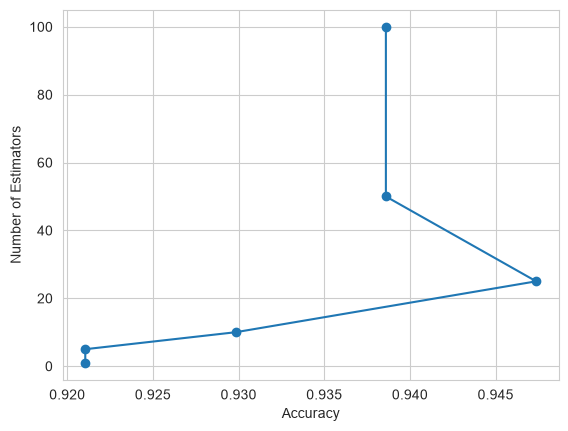

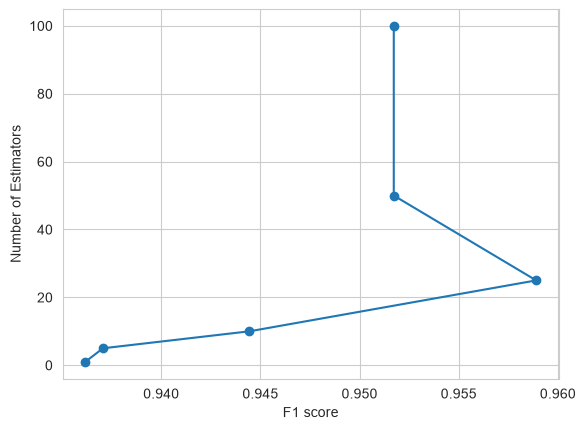

In [99]:
accuracy_data = results_df['Accuracy']
f1_data = results_df['F1']
num_of_estimators_data = results_df['Number_of_estimators']
plt.plot(accuracy_data, num_of_estimators_data, marker='o', linestyle='-')
plt.xlabel('Accuracy')
plt.ylabel('Number of Estimators')
plt.show()

plt.plot(f1_data, num_of_estimators_data, marker='o', linestyle='-')
plt.xlabel('F1 score')
plt.ylabel('Number of Estimators')
plt.show()

**Questions**
1. As the number of estimators increases the F1 and accuracy scores improve.
2. The performance does stop improving and actually sees diminishing returns.
3. When the number of estimators is 25 is when the performance is stable.
4. The more estimators the more the computational cost.

In [100]:
model_results = {'Model': [],
                 'Accuracy': [],
                 'F1': []
                 }

bag_tree = BaggingClassifier(
    estimator=DecisionTreeClassifier(
        random_state=42
    ),
    n_estimators=100,
    random_state=42
)

bag_tree.fit(X_train,y_train)
bag_tree_y_pred = bag_tree.predict(X_test)
bag_tree_f1 = f1_score(y_test, bag_tree_y_pred)
bag_tree_accuracy = accuracy_score(y_test, bag_tree_y_pred)

model_results['Model'].append('Bagged Decision Tree')
model_results['Accuracy'].append(bag_tree_accuracy)
model_results['F1'].append(bag_tree_f1)



In [101]:
bag_logistic = BaggingClassifier(
    estimator=LogisticRegression(
        max_iter=1000
    ),
    n_estimators=100,
    random_state=42
)

bag_logistic.fit(X_train,y_train)
bag_logistic_y_pred = bag_logistic.predict(X_test)
bag_logistic_f1 = f1_score(y_test, bag_logistic_y_pred)
bag_logistic_accuracy = accuracy_score(y_test, bag_logistic_y_pred)

model_results['Model'].append('Bagged Logistic Regression')
model_results['Accuracy'].append(bag_logistic_accuracy)
model_results['F1'].append(bag_logistic_f1)

c:\Users\lukew\Desktop\Coding\CSCI345_Machine-Learning_Fall2026\labs\lab06\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
c:\Users\lukew\Desktop\Coding\CSCI345_Machine-Learning_Fall2026\labs\lab06\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might al

In [102]:
bag_knn = BaggingClassifier(
    estimator=KNeighborsClassifier(),
    n_estimators=100,
    random_state=42
)

bag_knn.fit(X_train,y_train)
bag_knn_y_pred = bag_knn.predict(X_test)
bag_knn_f1 = f1_score(y_test, bag_knn_y_pred)
bag_knn_accuracy = accuracy_score(y_test, bag_knn_y_pred)

model_results['Model'].append('Bagged KNN')
model_results['Accuracy'].append(bag_knn_accuracy)
model_results['F1'].append(bag_knn_f1)

In [103]:
models_df = pd.DataFrame(model_results)
models_df.head()

,Model,Accuracy,F1
0,Bagged Decision Tree,0.938596,0.951724
1,Bagged Logistic Regression,0.956140,0.965517
2,Bagged KNN,0.912281,0.929577


**Questions**
1. The Logistic Regression model performed best.
2. Bagging did appear equally useful because all the model had accuracy and F1 scores above 90%
3. The Bagged decision tree benefitted the most.
4. It might be useful for models with high variance because it helps improve variance.

In [104]:
rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

In [105]:
rf.fit(
    X_train,
    y_train
)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

In [106]:
y_pred_rf = rf.predict(
    X_test
)

In [107]:
rf_accuracy = accuracy_score(
    y_test,
    y_pred_rf
)

rf_f1 = f1_score(
    y_test,
    y_pred_rf
)

print("Accuracy:", rf_accuracy)
print("F1:", rf_f1)

Accuracy: 0.956140350877193
F1: 0.9655172413793104


Decision Tree: 
Accuracy: 0.9122807017543859
F1: 0.9285714285714286
Bagged Decision Trees:
Accuracy: 0.9385964912280702
F1: 0.9517241379310345
Random Forest: 
Accuracy: 0.956140350877193
F1: 0.9655172413793104

**Questions**
1. They both have bootstrapping and they having random sets of features.
2. They do random feature selection.
3. They make the trees less correlated because the trees then don't ever start with the same features and have the same feature structure.
4. The Random Forest Model performed best.
5. It will help the ensemble because then you can get a more generalized result across very different models.

In [108]:
rf.feature_importances_

array([0.06867599, 0.00958431, 0.06957388, 0.04917215, 0.00559816,
       0.01171465, 0.05763806, 0.09088475, 0.00466601, 0.00448887,
       0.01677021, 0.00521386, 0.0096331 , 0.03310446, 0.00349852,
       0.00597922, 0.00431035, 0.00409824, 0.00401198, 0.00444169,
       0.09769574, 0.01859665, 0.07222637, 0.14001599, 0.0124362 ,
       0.01860002, 0.03434013, 0.12952961, 0.00833452, 0.00516632])

In [109]:
importance_mdi = pd.Series(
    rf.feature_importances_,
    index=X_train.columns
).sort_values(
    ascending=False
)

print(importance_mdi)

worst area                 0.140016
worst concave points       0.129530
worst radius               0.097696
mean concave points        0.090885
worst perimeter            0.072226
mean perimeter             0.069574
mean radius                0.068676
mean concavity             0.057638
mean area                  0.049172
worst concavity            0.034340
area error                 0.033104
worst compactness          0.018600
worst texture              0.018597
radius error               0.016770
worst smoothness           0.012436
mean compactness           0.011715
perimeter error            0.009633
mean texture               0.009584
worst symmetry             0.008335
compactness error          0.005979
mean smoothness            0.005598
texture error              0.005214
worst fractal dimension    0.005166
mean symmetry              0.004666
mean fractal dimension     0.004489
fractal dimension error    0.004442
concavity error            0.004310
concave points error       0

In [110]:
importance_mdi.sum()

np.float64(1.0)

**Questions**
1. The worst area had the highest MDI importance.
2. worst area, worst concave points, and worst radius
3. smoothness error
4. That the feature was very useful in making a prediction.
5. It is the thing that when a feature is used for prediction, calculates the importance of the feature.

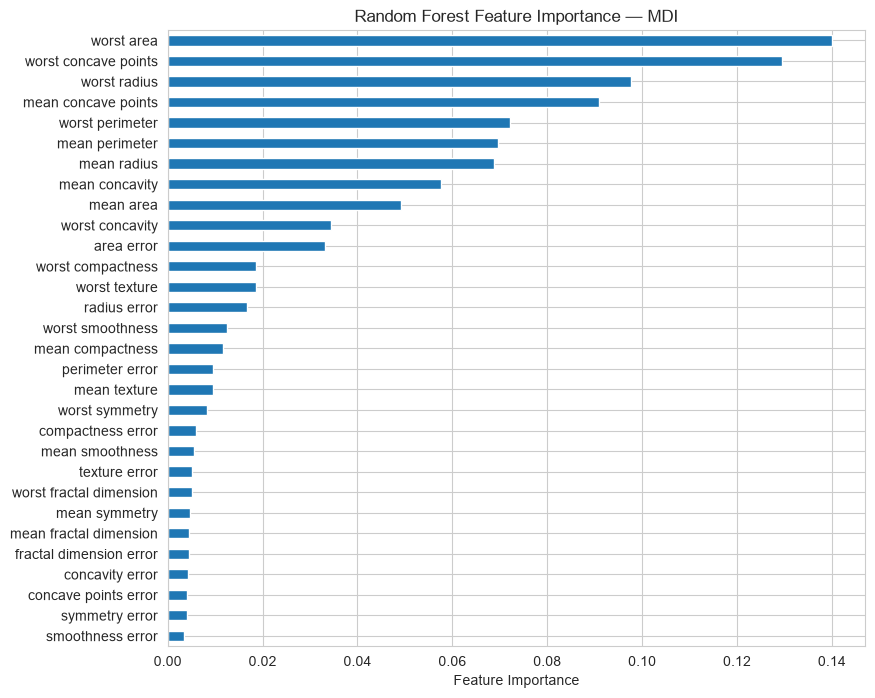

In [111]:
importance_mdi.sort_values().plot(
    kind="barh",
    figsize=(9, 8)
)

plt.xlabel(
    "Feature Importance"
)

plt.title(
    "Random Forest Feature Importance — MDI"
)

plt.show()

**Questions**
1. The model most relies most on worst area and worst concave points.
2. A couple features have a very high importance compared to the rest but they don't make up the majority.
3. There are features with very low importance values. 
4. No, it just means the feature isn't as important for predictions.


**Task 16**
No, this conclusion is not justified because that one feature cannot predict the entire prediction, it just shows how useful it is. Also, just because a feature has a high importance does not mean that the feature is the cause of the prediction. Furthermore, it does not mean that the feature is associated with that prediction.

In [112]:
result = permutation_importance(
    rf,
    X_test,
    y_test,
    n_repeats=10,
    random_state=42
)

In [113]:
importance_permutation = pd.Series(
    result.importances_mean,
    index=X_test.columns
).sort_values(
    ascending=False
)

print(importance_permutation)

compactness error          7.894737e-03
mean concave points        7.894737e-03
worst texture              7.017544e-03
worst area                 7.017544e-03
mean area                  5.263158e-03
mean smoothness            5.263158e-03
radius error               4.385965e-03
mean radius                4.385965e-03
concave points error       3.508772e-03
mean concavity             3.508772e-03
worst smoothness           2.631579e-03
worst concave points       2.631579e-03
mean fractal dimension     1.754386e-03
mean compactness           0.000000e+00
area error                 0.000000e+00
perimeter error            0.000000e+00
texture error              0.000000e+00
mean symmetry              0.000000e+00
mean perimeter             0.000000e+00
mean texture               0.000000e+00
concavity error            0.000000e+00
smoothness error           0.000000e+00
worst symmetry             0.000000e+00
fractal dimension error    0.000000e+00
symmetry error             0.000000e+00


**Questions**
1. The compactness error has the highest permutation importance.
2. Compactness error, mean concave points, and worst texture.
3. These results are not the same as the MDI results.
4. The worst area and worst radius changed their ranking.
5. Yes, there are features close to 0.

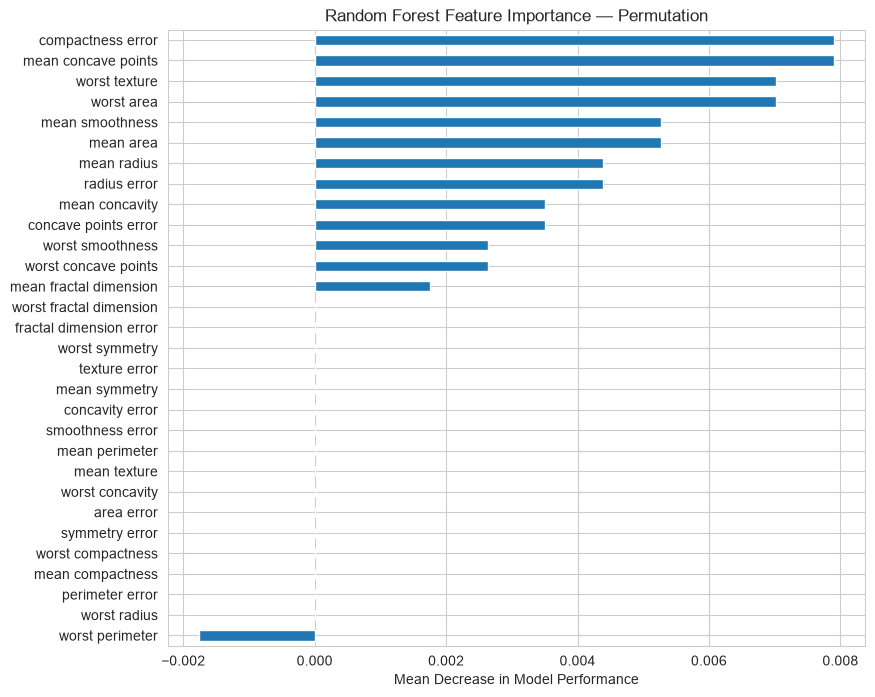

In [114]:
importance_permutation.sort_values().plot(
    kind="barh",
    figsize=(9, 8)
)

plt.xlabel(
    "Mean Decrease in Model Performance"
)

plt.title(
    "Random Forest Feature Importance — Permutation"
)

plt.show()

**Questions**
1. Compactness error and worst texture.
2. Worst perimeter and worst radius
3. It is like the worst radius completely changed positions from most important to least important.

In [115]:
importance_comparison = pd.DataFrame({
    "MDI": importance_mdi,
    "Permutation": importance_permutation
})

importance_comparison.sort_values(
    "MDI",
    ascending=False
)

,MDI,Permutation
worst area,0.140016,7.017544e-03
worst concave points,0.129530,2.631579e-03
worst radius,0.097696,-1.110223e-17
mean concave points,0.090885,7.894737e-03
worst perimeter,0.072226,-1.754386e-03
mean perimeter,0.069574,0.000000e+00
mean radius,0.068676,4.385965e-03
mean concavity,0.057638,3.508772e-03
mean area,0.049172,5.263158e-03
worst concavity,0.034340,0.000000e+00


1. MDI is based on tree splits.
2. Permutation important is based on model performance.
3. MDI looks at impurity reduction.
4. Permutation importance looks at performance decrease.
5. One limitation of MDI is with correlated features.
6. One advantage of permutation is working with correlated features.

**Questions** 
1. Worst area and worst concave points
2. Worst radius and worst perimeter
3. There are limitations to MDI which Permutation addresses.
4. Permutation importance.
5. It is looking at many many models.

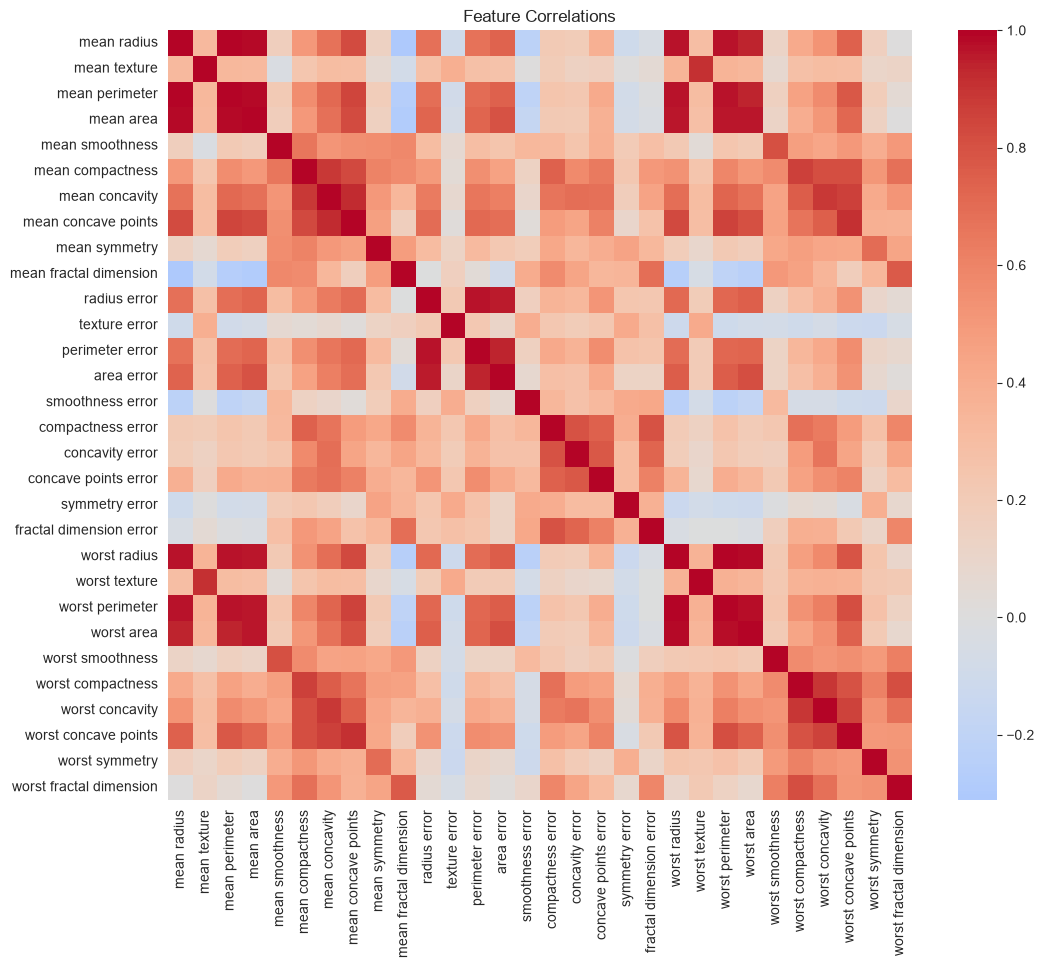

In [116]:
plt.figure(
    figsize=(12, 10)
)

sns.heatmap(
    X.corr(),
    cmap="coolwarm",
    center=0
)

plt.title(
    "Feature Correlations"
)

plt.show()

Worst radius and worst perimeter

**Questions**
1. Worst radius and worst perimeter
2. Since they are correlated, it is hard to distinguish between the two because they kind of combine into one feature.
3. There importance would be distributed equally among them.
4. Yes it could.
5. It is based on what the model finds most useful, not what the programmer.

In [117]:
voting_model = VotingClassifier(
    estimators=[
        (
            "tree",
            DecisionTreeClassifier(
                random_state=42
            )
        ),
        (
            "logistic",
            LogisticRegression(
                max_iter=1000
            )
        ),
        (
            "knn",
            KNeighborsClassifier()
        )
    ],
    voting="hard"
)

In [118]:
voting_model.fit(
    X_train,
    y_train
)

c:\Users\lukew\Desktop\Coding\CSCI345_Machine-Learning_Fall2026\labs\lab06\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,"estimators estimators: list of (str, estimator) tuplesInvoking the ``fit`` method on the ``VotingClassifier`` will fit clonesof those original estimators that will be stored in the class attribute``self.estimators_``. An estimator can be set to ``'drop'`` using:meth:`set_params`... versionchanged:: 0.21 ``'drop'`` is accepted. Using None was deprecated in 0.22 and support was removed in 0.24.","[('tree', ...), ('logistic', ...), ...]"
,"voting voting: {'hard', 'soft'}, default='hard'If 'hard', uses predicted class labels for majority rule voting.Else if 'soft', predicts the class label based on the argmax ofthe sums of the predicted probabilities, which is recommended foran ensemble of well-calibrated classifiers.",'hard'
,"weights weights: array-like of shape (n_classifiers,), default=NoneSequence of weights (`float` or `int`) to weight the occurrences ofpredicted class labels (`hard` voting) or class probabilitiesbefore averaging (`soft` voting). Uses uniform weights if `None`.",None
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for ``fit``.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionadded:: 0.18",None
,"flatten_transform flatten_transform: bool, default=TrueAffects shape of transform output only when voting='soft'If voting='soft' and flatten_transform=True, transform method returnsmatrix with shape (n_samples, n_classifiers * n_classes). Ifflatten_transform=False, it returns(n_classifiers, n_samples, n_classes).",True
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting will be printed as itis completed... versionadded:: 0.23",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels.","ndarray[int64](2,)","[0,1]"
"estimators_ estimators_: list of classifiersThe collection of fitted sub-estimators as defined in ``estimators``that are not 'drop'. Note that sub-estimators are always fitted oninteger-encoded labels (see ``le_`` attribute). When ``y`` containsnon-integer class labels (e.g. strings), use ``le_.inverse_transform``to map predictions back to the original label space.",list,"[DecisionTreeC...ndom_state=42), LogisticRegre...max_iter=1000), KNeighborsClassifier()]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimators expose such an attribute when fit... versionadded:: 1.0","ndarray[object](30,)","['mean radius','mean texture','mean perimeter',...,'worst concave points', 'worst symmetry','worst fractal dimension']"
le_ le_: :class:`~sklearn.preprocessing.LabelEncoder`Transformer used to encode the labels during fit and decode duringprediction. Sub-estimators in ``estimators_`` are fitted on theinteger-encoded labels produced by this encoder.,LabelEncoder,LabelEncoder()


In [119]:
y_pred_voting = voting_model.predict(
    X_test
)

In [120]:
accuracy_voting = accuracy_score(y_pred_voting, y_test)
f1_voting = f1_score(y_pred_voting, y_test)
print('Accuracy:' + str(accuracy_voting))
print('F1 score:' + str(f1_voting))

Accuracy:0.9473684210526315
F1 score:0.9583333333333334


In [121]:


final_comparison = {'Model': ['Bagged Logistic Regression','Random Forest','Voting Classifier','Bagged Decision Tree','Bagged KNN','Decision Tree'],
                    'Accuracy': [0.956140,0.956140350877193,0.9473684210526315,0.9385964912280702,0.912281,0.9122807017543859],
                    'F1 Score': [0.965517,0.9655172413793104,0.9583333333333334,0.9517241379310345,0.929577,0.9285714285714286]
                    }
final_comparison_df = pd.DataFrame(final_comparison)
final_comparison_df

,Model,Accuracy,F1 Score
0,Bagged Logistic Regression,0.956140,0.965517
1,Random Forest,0.956140,0.965517
2,Voting Classifier,0.947368,0.958333
3,Bagged Decision Tree,0.938596,0.951724
4,Bagged KNN,0.912281,0.929577
5,Decision Tree,0.912281,0.928571


**Bootstrapping**
1. It is a resampling technique
2. It is to help give us different versions of training data.
3. When randomly selecting observations it will repeat some which will make some be left out.
4. So each time they are used it is like the original dataset, making sure training is still upheld.
**Bagging**
1. A method of training many models on bootstrap samples. 
2. Each model is trained on a single bootstrap sample, then it combines the predictions.
3. It either averages or takes the majority vote from the models from the models to make a prediction.
4. It takes a bunch of unstable models(high variance) and then combines them to predict something stable(less variance).
5. It helps reduce variance.
**Random Forest**
1. It combines bagging and random feature selection.
2. It makes decision trees less correlated.
3. So that trees actually make predictions well and it helps with generalization.
4. Bagging does not have random feature selection.
**MDI**
1. Feature importance based on tree splits
2. Feature importance based on model performance.
3. MDI has limitations which permutation addresses
4. The features in a way combine and become one feature.
5. It just states how useful the feature was in predicting the outcome.
**Model Selection**
1. The Bagged Logistic Regression model.
2. It was about 4% better in both areas.
3. Most times it did but sometimes actually reduced performance.
4. The Logistic Regression model benefitted the most. 
5. It uses a bunch of different models making predictions and then averages or selects the majority.
6. It has a high computational cost.
7. I would not because accuracy alone does not tell the entire story. I want to know which features were helpful and how confident the model was.